# Exploration des catastrophes EM-DAT

**Objectif** : Décrire la base EM-DAT : valeurs manquantes par type de catastrophe et par année, distribution du nombre de décès, transformation logarithmique, corrélations.

**Données**

- `public_emdat_project.csv` : extrait EM-DAT (CRED), non redistribué dans ce dépôt (voir le README).
- Source et licence : voir les sections Source et Licence du README.

**Exécution** : installer les dépendances (`pip install -r requirements.txt`), puis lancer « Restart & Run All » depuis la racine du dépôt.


In [1]:
from pathlib import Path

FICHIERS_ATTENDUS = ['public_emdat_project.csv']
manquants = [f for f in FICHIERS_ATTENDUS if not Path(f).exists()]
if manquants:
    raise FileNotFoundError(f"Fichiers manquants : {manquants}. Voir la section « Données » du README.")
print('Fichiers présents :', FICHIERS_ATTENDUS)


Fichiers présents : ['public_emdat_project.csv']


In [2]:
import pandas as pd

In [3]:
df = pd.read_csv("public_emdat_project.csv", encoding="ISO-8859-1")
df.dtypes

DisNo.                                           str
Historic                                         str
Classification Key                               str
Disaster Group                                   str
Disaster Subgroup                                str
Disaster Type                                    str
Disaster Subtype                                 str
External IDs                                     str
Event Name                                       str
ISO                                              str
Country                                          str
Subregion                                        str
Region                                           str
Location                                         str
Origin                                           str
Associated Types                                 str
OFDA/BHA Response                                str
Appeal                                           str
Declaration                                   

In [4]:
df['Total Deaths'].describe()

count     12655.000000
mean        135.976847
std        3088.333299
min           0.000000
25%           9.000000
50%          16.000000
75%          32.000000
max      222570.000000
Name: Total Deaths, dtype: float64

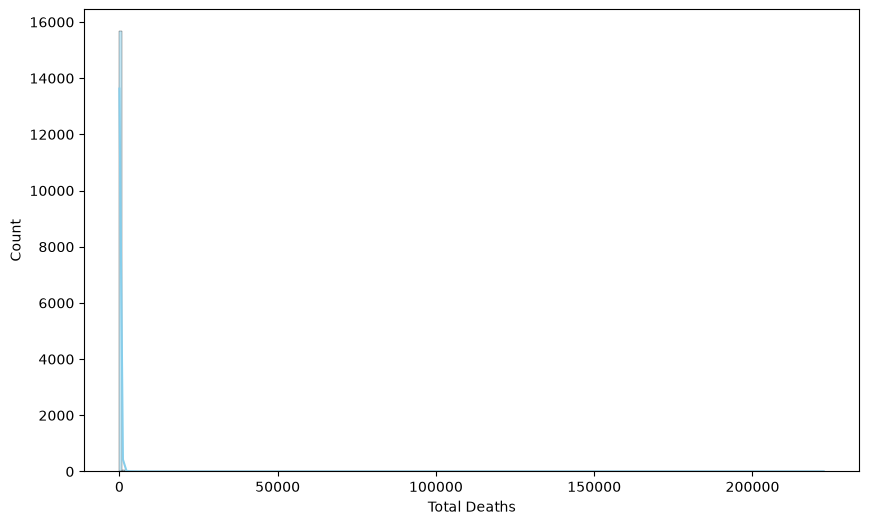

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np # Assure-toi que numpy est importé

# On applique log1p pour la visualisation
plt.figure(figsize=(10, 6))
sns.histplot((df['Total Deaths'].fillna(0)), kde=True, color="skyblue")

plt.show()

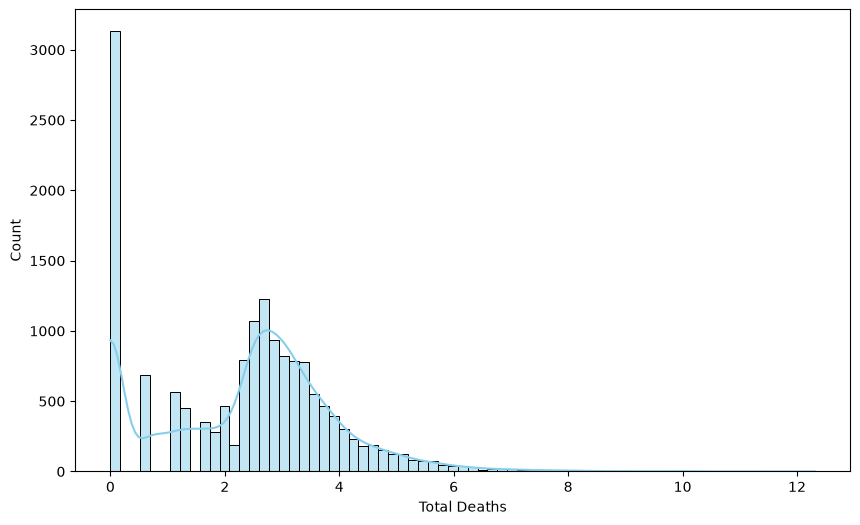

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np # Assure-toi que numpy est importé

# On applique log1p pour la visualisation
plt.figure(figsize=(10, 6))
sns.histplot(np.log1p(df['Total Deaths'].fillna(0)), kde=True, color="skyblue")

plt.show()

In [7]:
df[['Start Year', 'Start Month', 'CPI', 'Magnitude', 'Total Deaths']].corr()

,Start Year,Start Month,CPI,Magnitude,Total Deaths
Start Year,1.000000,-0.041685,0.982875,0.020131,-0.006457
Start Month,-0.041685,1.000000,-0.021358,0.015671,-0.003982
CPI,0.982875,-0.021358,1.000000,0.015035,-0.003675
Magnitude,0.020131,0.015671,0.015035,1.000000,-0.004573
Total Deaths,-0.006457,-0.003982,-0.003675,-0.004573,1.000000


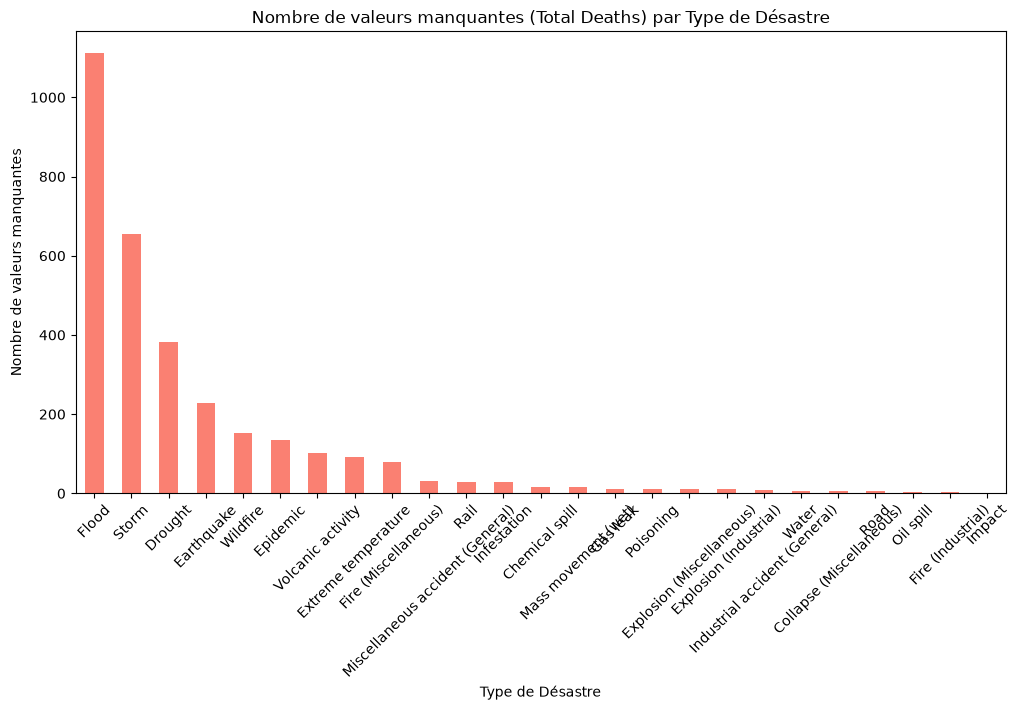

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculer le nombre de valeurs manquantes par type de désastre
missing_by_type = df[df['Total Deaths'].isna()].groupby('Disaster Type').size()

# 2. Créer le graphique
plt.figure(figsize=(12, 6))
missing_by_type.sort_values(ascending=False).plot(kind='bar', color='salmon')

plt.title('Nombre de valeurs manquantes (Total Deaths) par Type de Désastre')
plt.xlabel('Type de Désastre')
plt.ylabel('Nombre de valeurs manquantes')
plt.xticks(rotation=45)
plt.show()

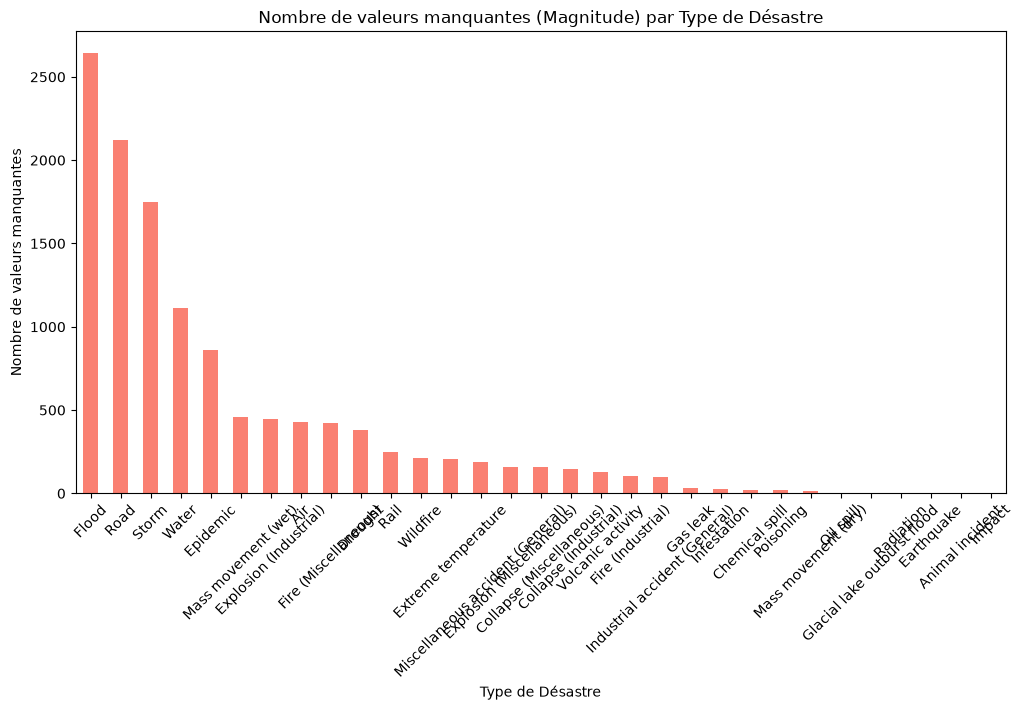

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculer le nombre de valeurs manquantes par type de désastre
missing_by_type = df[df['Magnitude'].isna()].groupby('Disaster Type').size()

# 2. Créer le graphique
plt.figure(figsize=(12, 6))
missing_by_type.sort_values(ascending=False).plot(kind='bar', color='salmon')

plt.title('Nombre de valeurs manquantes (Magnitude) par Type de Désastre')
plt.xlabel('Type de Désastre')
plt.ylabel('Nombre de valeurs manquantes')
plt.xticks(rotation=45)
plt.show()

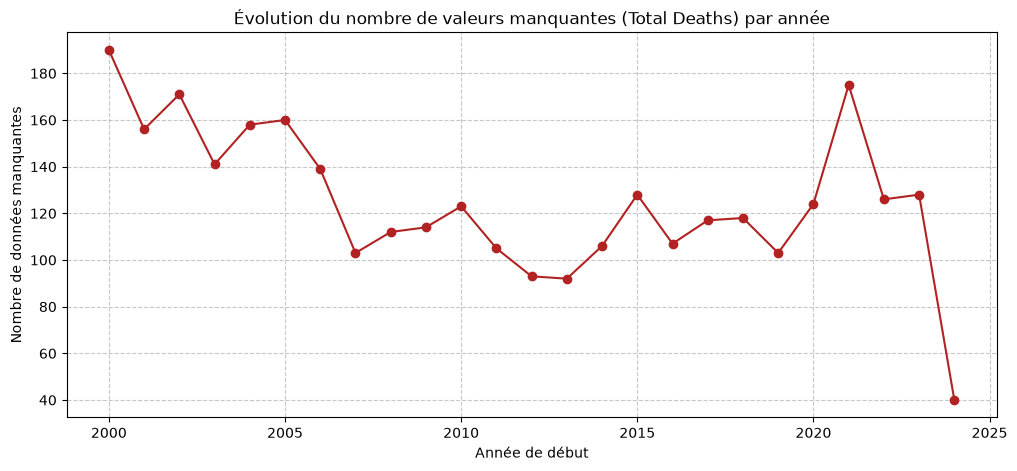

In [10]:
import matplotlib.pyplot as plt

# 1. Grouper par année et compter le nombre de NaN dans 'Total Deaths'
missing_time = df.groupby('Start Year')['Total Deaths'].apply(lambda x: x.isna().sum())

# 2. Tracer la courbe
plt.figure(figsize=(12, 5))
missing_time.plot(kind='line', marker='o', color='firebrick', linestyle='-')

plt.title('Évolution du nombre de valeurs manquantes (Total Deaths) par année')
plt.xlabel('Année de début')
plt.ylabel('Nombre de données manquantes')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

## Interprétation et limites

**Distribution du nombre de décès.** `Total Deaths` est très asymétrique : médiane de 16 décès, moyenne de 136, maximum de 222 570 (cellule `df['Total Deaths'].describe()`). La moyenne est tirée vers le haut par quelques catastrophes très meurtrières. La transformation `log1p` rend la distribution plus lisible, comme le montrent les deux histogrammes avant et après transformation.

**Corrélations.** `CPI` et l'année de début sont presque colinéaires (0,98). Ces deux variables portent donc la même information temporelle : il faut n'en garder qu'une dans un modèle. Le nombre de décès n'est presque pas corrélé linéairement aux autres variables numériques (entre -0,007 et -0,004). Cela ne signifie pas qu'il n'existe aucun lien : une corrélation de Pearson ne capte que les relations linéaires, et la forte asymétrie de la cible la perturbe.

**Valeurs manquantes.** Les graphiques montrent les manques par type de catastrophe et par année, sans pourcentage. La part de `Magnitude` manquante est détaillée dans le notebook 02.

**Limites.**
- Les corrélations sont calculées sur une variable très asymétrique, ce qui réduit leur pertinence.
- Les données sont observationnelles : elles décrivent des associations, pas des causes.
- Hypothèse à vérifier : les manques de `Magnitude` ne sont probablement pas répartis au hasard (ils dépendent du type de catastrophe et de l'année).
